# DS02 · Pencere eğimi

Bir pencerenin ortalaması ve standart sapması, kanalın hangi yönde değiştiğini
göstermez. 500 → 510 → 520 ile 520 → 510 → 500 dizilerinin ortalaması ve
standart sapması aynıdır, eğimlerinin işaretleri terstir.

Eski `mean_to_date` uçuş geçmişini özetler. `slope` tek pencere içindeki
değişimi anlatır. Bu deney 36 girdiye yalnızca 18 pencere eğimi ekler.

## Ayarlar ve GPU kontrolü

Küçük XGBoost denemesi mevcut Colab oturumunda CUDA ile eğitim ve tahmini
doğrular. Başarılı olursa 54 girdili deney çalışabilir.

In [1]:
import hashlib
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

from tempfile import NamedTemporaryFile

import xgboost

LEARNING_RATE = 0.05
MAX_TREES = 3000
EARLY_STOPPING_ROUNDS = 50
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=LEARNING_RATE,
    max_depth=6,
    random_state=42,
)



def require_cuda_model(model):
    config = json.loads(model.get_booster().save_config())
    device = config["learner"]["generic_param"]["device"]
    if not device.startswith("cuda"):
        raise RuntimeError(f"XGBoost CPU’ya düştü (cihaz: {device}).")


def check_cuda():
    try:
        x = np.arange(32, dtype=np.float32).reshape(16, 2)
        probe = XGBRegressor(device="cuda", tree_method="hist", n_estimators=1, max_depth=2)
        probe.fit(x, np.arange(16, dtype=np.float32))
        require_cuda_model(probe)
        import cupy as cp

        prediction = probe.get_booster().inplace_predict(cp.asarray(x))
        if not isinstance(prediction, cp.ndarray) or prediction.shape != (len(x),):
            raise RuntimeError("CUDA tahmin kontrolü başarısız.")
        name = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)["name"]
        return cp, name.decode("utf-8") if isinstance(name, bytes) else str(name)
    except Exception as error:
        raise RuntimeError(
            "CUDA doğrulanamadı. Colab’da GPU çalışma zamanını seçin. Uzun eğitim başlatılmadı."
        ) from error


cp, gpu_name = check_cuda()
print(f"GPU doğrulandı: {gpu_name} | XGBoost {xgboost.__version__}", flush=True)

GPU doğrulandı: Tesla T4 | XGBoost 3.4.1


## Drive ve pencere sınırları

Drive zaten bağlıysa mevcut bağlantı kullanılır. DS02 dev verisi ve V04 ile
aynı 256/256 metadata’sı okunur. CSV eksikse HDF5 uçuş sınırlarından üretilir.

In [2]:
if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v05_pencere_egimi"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev sütun sırası beklenen unit, cycle ile başlamıyor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 içinde 446 benzersiz dev uçuşu bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere uçuş sınırını aşıyor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata içinde HDF5 ile eşleşmeyen uçuş var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Hazır metadata kullanılıyor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} uçuş ve {len(windows):,} benzersiz pencere doğrulandı. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Hazır metadata kullanılıyor: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Pencere özellikleri

Her uçuş tek blok halinde okunur. V04’teki 36 özellik aynı sırayla hesaplanır.
Eğim için her kanalın 256 değerine, t = 0, …, 255 üzerinde sabit terimli
bir en küçük kareler doğrusu uydurulur. Eğim, **örnek adımı başına kanal
değerindeki değişim** birimindedir. Önce üç yapay örneği, ardından Motor 2
uçuş 1’in ilk pencerelerinde T48 değerlerini kontrol edin.

In [3]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def window_slope(values):
    time = np.arange(values.shape[1], dtype=np.float64)
    centered_time = time - time.mean()
    return np.einsum("t,ntc->nc", centered_time, values, dtype=np.float64) / np.dot(
        centered_time, centered_time
    )


time = np.arange(WINDOW_SIZE, dtype=np.float64)
toy = np.column_stack([np.full_like(time, 500), 500 + 10 * time, 520 - 10 * time])
np.testing.assert_allclose(window_slope(toy[None, :, :])[0], [0, 10, -10], rtol=0, atol=1e-12)
print("Eğim kontrolü (sabit, artan, azalan): 0, +10, −10")


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36
        slope_columns = [f"{name}_slope" for _, names in groups for name in names]

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            window_features = []
            slopes = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])
                slopes.append(window_slope(window_rows))

            stats = pd.DataFrame(np.hstack([*window_features, *slopes]), index=flight_windows.index, columns=[*feature_columns, *slope_columns])
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    return v02, feature_columns, slope_columns


windows, features_36, slope_columns = extract_features(h5_path, metadata, dev_flights)
actual_flights = (
    dev_flights[[*FLIGHT_KEYS, "rul"]].rename(columns={"rul": "RUL"})
    .sort_values(FLIGHT_KEYS, ignore_index=True)
)
units = sorted(windows["unit"].unique())
assert len(units) == 6 and len(actual_flights) == 446
assert not actual_flights.duplicated(FLIGHT_KEYS).any()
assert len(windows[FLIGHT_KEYS].drop_duplicates()) == 446
assert windows[features_36].shape == (20_339, 36)
print(f"{len(units)} motor, {len(actual_flights)} uçuş, {len(windows):,} pencere, {len(features_36)} girdi")

features_54 = [*features_36, *slope_columns]
assert len(slope_columns) == 18 and len(set(features_54)) == 54
assert windows[features_54].shape == (20_339, 54)
assert np.isfinite(windows[features_54].to_numpy()).all()
pd.testing.assert_frame_equal(
    windows[[("RUL" if column == "rul" else column) for column in META_COLUMNS]],
    metadata.rename(columns={"rul": "RUL"}),
    check_exact=True, check_dtype=False,
)
t48 = next(column.removesuffix("_mean") for column in features_36 if column.endswith("_T48_mean"))
preview_columns = [f"{t48}_{suffix}" for suffix in ("mean", "std", "slope")]
display(
    windows.loc[(windows["unit"] == 2) & (windows["cycle"] == 1), ["window_id", *preview_columns]]
    .head().rename(columns={column: f"T48_{column.rsplit('_', 1)[1]}" for column in preview_columns})
)
print(f"54 girdili tablo: {windows[features_54].shape}")

Eğim kontrolü (sabit, artan, azalan): 0, +10, −10
6 motor, 446 uçuş, 20,339 pencere, 36 girdi


,window_id,T48_mean,T48_std,T48_slope
0,0,1817.373244,0.984106,0.002493
1,1,1807.247118,6.264073,-0.084014
2,2,1788.369342,5.115545,-0.068845
3,3,1772.193547,4.336451,-0.058466
4,4,1758.375247,3.666448,-0.048659


54 girdili tablo: (20339, 54)


## Motor bazlı eğitim

V04’teki ağırlıklarla her eğitim uçuşu eşit katkı alır. Dış motor eğitimden
ayrılır. Kalan beş motor sırayla iç doğrulamaya alınır. Pencere medyanlarından
hesaplanan uçuş RMSE’si ağaç sayısını seçer. Beş sayının medyanı dış modelde
kullanılır. İlerleme satırları hangi motorun işlendiğini gösterir.

In [4]:
def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()




def make_flight_rmse(validation):
    flight_codes = validation.groupby(FLIGHT_KEYS, sort=False).ngroup().to_numpy()
    actual = validation.groupby(FLIGHT_KEYS, sort=False)["RUL"].first().to_numpy()

    def flight_rmse(_window_rul, predictions):
        medians = pd.Series(predictions).groupby(flight_codes, sort=False).median().to_numpy()
        return float(np.sqrt(np.mean(np.square(medians - actual))))

    return flight_rmse




def fit_outer_motor(outer_unit):
    training = windows.loc[windows["unit"] != outer_unit]
    held_out = windows.loc[windows["unit"] == outer_unit]
    params = {**model_params, "device": "cuda"}
    inner_results = []
    for number, inner_unit in enumerate(sorted(training["unit"].unique()), start=1):
        label = f"Dış motor {outer_unit} | İç motor {inner_unit} | Tur {number}/5"
        print(f"{label} | Başladı", flush=True)
        inner_train = training.loc[training["unit"] != inner_unit]
        inner_valid = training.loc[training["unit"] == inner_unit]
        inner_params = {**params, "eval_metric": make_flight_rmse(inner_valid),
                        "disable_default_eval_metric": True}
        model = XGBRegressor(**inner_params, n_estimators=MAX_TREES,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(
            inner_train[features_54], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[features_54], inner_valid["RUL"])],
            verbose=False,
        )
        require_cuda_model(model)
        selected = model.best_iteration + 1
        tried = len(model.evals_result()["validation_0"]["flight_rmse"])
        inner_results.append(dict(unit=int(inner_unit), selected=selected, tried=tried))
        print(f"{label} | Bitti | {selected} ağaç seçildi ({tried} denendi)", flush=True)

    rounds = int(np.median([item["selected"] for item in inner_results]))
    print(f"Dış motor {outer_unit} | Son eğitim: {rounds} ağaç", flush=True)
    model = XGBRegressor(**params, n_estimators=rounds)
    model.fit(training[features_54], training["RUL"], sample_weight=flight_weights(training))
    require_cuda_model(model)
    flights = held_out[[*FLIGHT_KEYS, "RUL"]].copy()
    gpu_input = cp.asarray(held_out[features_54].to_numpy())
    flights["prediction"] = cp.asnumpy(
        model.get_booster().inplace_predict(gpu_input, validate_features=False)
    )
    flights = flights.groupby(FLIGHT_KEYS, as_index=False).agg(
        RUL=("RUL", "first"), prediction=("prediction", "median")
    )
    return flights, inner_results, rounds

## V04 karşılaştırma kaydı

V04’ün 0,05 koşusundaki altı motor kaydı doğrulanır. Ortak 36 girdinin
parmak izi, ayarlar, uçuş anahtarları ve gerçek RUL değerleri eşleşmelidir.
Birleştirilen 446 tahminin beklenen yuvarlanmış hataları MAE 7,285 ve RMSE
10,131’dir. Referans kullanılamazsa 54 girdili koşu devam eder.

In [5]:
input_columns = ["window_id", *FLIGHT_KEYS, "RUL", *features_36]
protocol = {
    "model": "V02-36",
    "split": "DS02-006_dev",
    "window_size": WINDOW_SIZE,
    "stride": STRIDE,
    "input_columns": input_columns,
    "input_sha256": hashlib.sha256(windows[input_columns].to_numpy(dtype="<f8").tobytes()).hexdigest(),
    "outer_units": [int(unit) for unit in units],
    "inner_split": "leave_one_engine_out_within_outer_training",
    "model_params": model_params.copy(),
    "max_trees": MAX_TREES,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "selection": "flight_rmse_of_window_medians_then_median_best_rounds",
    "weights": "inverse_windows_per_flight_normalized_to_mean_one",
    "prediction": "flight_median_of_outer_held_out_windows",
}
def raw_metrics(actual, predicted):
    errors = np.asarray(predicted, dtype=float) - np.asarray(actual, dtype=float)
    return np.abs(errors).mean(), np.sqrt(np.square(errors).mean())




def validate_flights(frame, expected):
    columns = [*FLIGHT_KEYS, "RUL"]
    frame = frame[[*columns, "prediction"]].sort_values(FLIGHT_KEYS, ignore_index=True)
    if frame.duplicated(FLIGHT_KEYS).any():
        raise ValueError("Tahmin kaydında tekrar eden uçuş var.")
    pd.testing.assert_frame_equal(frame[columns], expected[columns], check_exact=True, check_dtype=False)
    if not np.isfinite(frame["prediction"].to_numpy(dtype=float)).all():
        raise ValueError("Tahminler sonlu olmalı.")
    return frame



def expected_motor(unit):
    return actual_flights.loc[actual_flights["unit"] == unit].reset_index(drop=True)


def input_fingerprint(columns):
    return hashlib.sha256(windows[columns].to_numpy(dtype="<f8").tobytes()).hexdigest()


def motor_protocol(unit, *, baseline=False):
    return {
        **protocol,
        "model": "V02-36" if baseline else "V05-54-slope",
        "input_columns": input_columns if baseline else slope_input_columns,
        "input_sha256": protocol["input_sha256"] if baseline else slope_input_hash,
        "model_params": {**model_params, "device": "cuda"},
        "outer_unit": int(unit),
        "xgboost_version": xgboost.__version__,
    }


slope_input_columns = ["window_id", *FLIGHT_KEYS, "RUL", *features_54]
slope_input_hash = input_fingerprint(slope_input_columns)


def load_reference(folder):
    frames = []
    for unit in units:
        path = folder / f"oran_0.05_motor_{unit}.json"
        try:
            record = json.loads(path.read_text(encoding="utf-8"))
            recorded = record["protocol"].copy()
            version = recorded.pop("xgboost_version")
            expected = motor_protocol(unit, baseline=True)
            expected.pop("xgboost_version")
            if not isinstance(version, str) or not version or recorded != expected:
                raise ValueError("Ayarlar veya ortak 36 girdinin parmak izi eşleşmiyor.")
            frames.append(validate_flights(pd.DataFrame(record["flights"]), expected_motor(unit)))
        except (OSError, ValueError, TypeError, KeyError, AttributeError, AssertionError) as error:
            return None, f"V04 referansı kullanılamadı (Motor {unit}): {error}"

    reference = validate_flights(pd.concat(frames, ignore_index=True), actual_flights)
    observed = tuple(f"{value:.3f}" for value in raw_metrics(reference["RUL"], reference["prediction"]))
    if observed != ("7.285", "10.131"):
        return None, f"V04 referans metrikleri eşleşmedi: MAE {observed[0]}, RMSE {observed[1]}."
    return reference, "V04 kaydı doğrulandı: ortak 36 girdi, 446 uçuş ve referans metrikleri eşleşti."


reference, reference_status = load_reference(
    drive_root / "deneyler" / "xgboost_v04_ogrenme_orani" / "motor_kayitlari"
)
print(reference_status, flush=True)

V04 kaydı doğrulandı: ortak 36 girdi, 446 uçuş ve referans metrikleri eşleşti.


## Tamamlanan motorları kaydetme

Her dış motor bitince uçuş tahminleri, beş iç turun seçtiği ağaç sayıları
ve deney ayarları Drive’a kaydedilir. Yeniden çalıştırmada ayarları ve uçuşları
doğrulanan motorlar atlanır.

In [6]:
def load_motor(path, unit):
    try:
        record = json.loads(path.read_text(encoding="utf-8"))
        if record["protocol"] != motor_protocol(unit):
            return None
        inner = record["inner"]
        if [item["unit"] for item in inner] != sorted(int(other) for other in units if other != unit):
            return None
        if any(not isinstance(item["selected"], int) or not isinstance(item["tried"], int)
               or not 1 <= item["selected"] <= item["tried"] <= MAX_TREES for item in inner):
            return None
        if record["rounds"] != int(np.median([item["selected"] for item in inner])):
            return None
        flights = validate_flights(pd.DataFrame(record["flights"]), expected_motor(unit))
        return flights, record
    except (OSError, ValueError, TypeError, KeyError, AssertionError):
        return None


def save_motor(path, record):
    path.parent.mkdir(parents=True, exist_ok=True)
    with NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent, suffix=".tmp", delete=False) as temporary:
        json.dump(record, temporary, ensure_ascii=False, allow_nan=False)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)




slope_flights = []
tree_rows = []
for unit in units:
    path = output_dir / "motor_kayitlari" / f"motor_{unit}.json"
    cached = load_motor(path, unit)
    if cached is None:
        flights, inner, rounds = fit_outer_motor(unit)
        flights = validate_flights(flights, expected_motor(unit))
        record = dict(protocol=motor_protocol(unit), inner=inner, rounds=rounds,
                      flights=flights.to_dict("records"))
        save_motor(path, record)
        print(f"Dış motor {unit} | Kaydedildi", flush=True)
    else:
        flights, record = cached
        print(f"Dış motor {unit} | Kayıt kullanıldı", flush=True)
    slope_flights.append(flights)
    tree_rows.append({"Motor": int(unit), "Seçilen ağaç": record["rounds"],
                      "İç tur seçimleri": [item["selected"] for item in record["inner"]]})
slope_predictions = validate_flights(pd.concat(slope_flights, ignore_index=True), actual_flights)
tree_summary = pd.DataFrame(tree_rows)
display(tree_summary)

Dış motor 2 | İç motor 5 | Tur 1/5 | Başladı
Dış motor 2 | İç motor 5 | Tur 1/5 | Bitti | 1914 ağaç seçildi (1964 denendi)
Dış motor 2 | İç motor 10 | Tur 2/5 | Başladı
Dış motor 2 | İç motor 10 | Tur 2/5 | Bitti | 875 ağaç seçildi (925 denendi)
Dış motor 2 | İç motor 16 | Tur 3/5 | Başladı
Dış motor 2 | İç motor 16 | Tur 3/5 | Bitti | 359 ağaç seçildi (409 denendi)
Dış motor 2 | İç motor 18 | Tur 4/5 | Başladı
Dış motor 2 | İç motor 18 | Tur 4/5 | Bitti | 1144 ağaç seçildi (1194 denendi)
Dış motor 2 | İç motor 20 | Tur 5/5 | Başladı
Dış motor 2 | İç motor 20 | Tur 5/5 | Bitti | 574 ağaç seçildi (624 denendi)
Dış motor 2 | Son eğitim: 875 ağaç
Dış motor 2 | Kaydedildi
Dış motor 5 | İç motor 2 | Tur 1/5 | Başladı
Dış motor 5 | İç motor 2 | Tur 1/5 | Bitti | 1599 ağaç seçildi (1649 denendi)
Dış motor 5 | İç motor 10 | Tur 2/5 | Başladı
Dış motor 5 | İç motor 10 | Tur 2/5 | Bitti | 1499 ağaç seçildi (1549 denendi)
Dış motor 5 | İç motor 16 | Tur 3/5 | Başladı
Dış motor 5 | İç motor 16 | T

,Motor,Seçilen ağaç,İç tur seçimleri
0,2,875,"[1914, 875, 359, 1144, 574]"
1,5,696,"[1599, 1499, 385, 696, 628]"
2,10,582,"[404, 843, 623, 582, 329]"
3,16,575,"[469, 1024, 946, 575, 474]"
4,18,681,"[681, 1010, 891, 392, 618]"
5,20,788,"[788, 981, 742, 770, 917]"


## Uçuş bazlı sonuçlar

Hata, kırpılmamış uçuş tahminlerinden hesaplanır. Genel satır 446 uçuşu
birlikte değerlendirir. 54 − 36 farkının negatif olması hatanın azaldığını
gösterir. V04 kaydı eksikse ilgili hücreler boş kalır.

In [7]:
available = {"36 özellik": reference, "36 + 18 eğim": slope_predictions}
flight_predictions = actual_flights.copy()
for label, frame in available.items():
    if frame is not None:
        flight_predictions[label] = frame["prediction"].to_numpy()

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("Tümü", flight_predictions)]:
    row = {"Motor": label, "Uçuş sayısı": len(flights)}
    for column, count in zip(available, (36, 54)):
        mae, rmse = raw_metrics(flights["RUL"], flights[column]) if column in flights else (np.nan, np.nan)
        row[f"MAE {count}"], row[f"RMSE {count}"] = mae, rmse
    for metric in ("MAE", "RMSE"):
        row[f"{metric} farkı (54 − 36)"] = row[f"{metric} 54"] - row[f"{metric} 36"]
    metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
negative_counts = pd.DataFrame([
    {"Model": label, "Negatif tahminli uçuş": int(frame["prediction"].lt(0).sum()) if frame is not None else pd.NA}
    for label, frame in available.items()
])
display(metrics.round(3))
display(negative_counts)
print(reference_status)

,Motor,Uçuş sayısı,MAE 36,RMSE 36,MAE 54,RMSE 54,MAE farkı (54 − 36),RMSE farkı (54 − 36)
0,2,75,7.185,8.761,6.925,8.526,-0.260,-0.235
1,5,89,8.876,14.056,8.926,14.186,0.050,0.130
2,10,82,7.087,10.226,7.392,10.521,0.305,0.294
3,16,63,7.420,8.857,7.437,8.858,0.017,0.001
4,18,71,5.369,6.943,5.401,6.966,0.032,0.023
5,20,66,7.432,9.126,7.397,9.034,-0.035,-0.092
6,Tümü,446,7.285,10.131,7.310,10.179,0.024,0.048


,Model,Negatif tahminli uçuş
0,36 özellik,10
1,36 + 18 eğim,12


V04 kaydı doğrulandı: ortak 36 girdi, 446 uçuş ve referans metrikleri eşleşti.


## Motor grafikleri

Her motor için gerçek RUL ve mevcut iki tahmin aynı eksendedir.
Negatif tahminler grafikte korunur.

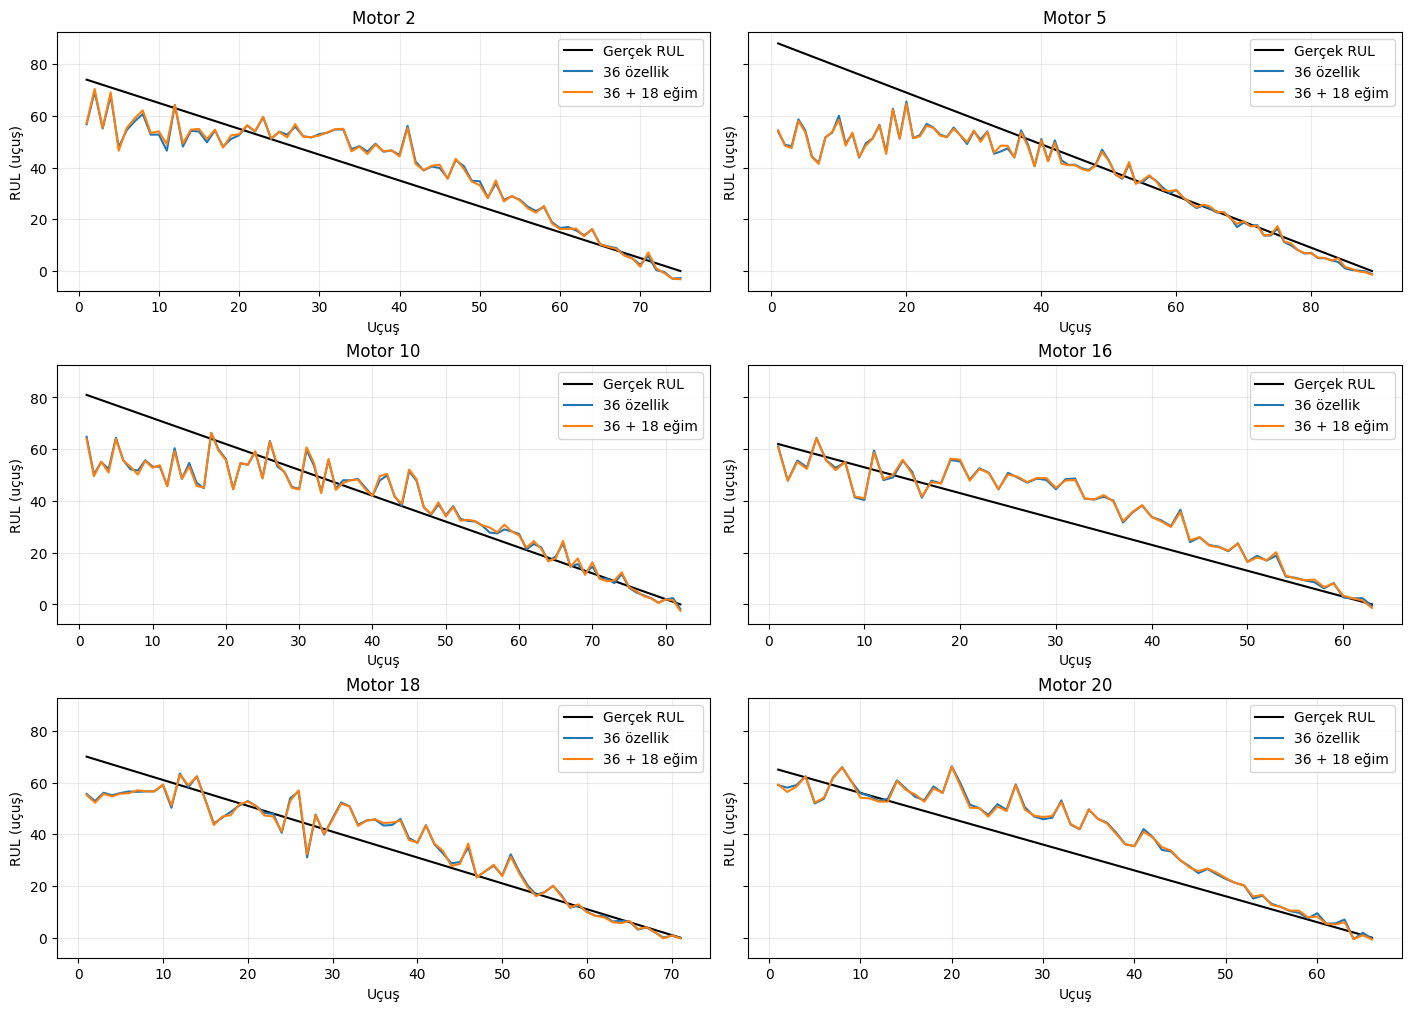

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], color="black", label="Gerçek RUL")
    for label in available:
        if label in flights:
            ax.plot(flights["cycle"], flights[label], label=label)
    ax.set(title=f"Motor {unit}", xlabel="Uçuş", ylabel="RUL (uçuş)")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Drive çıktıları

Uçuş tahminleri, hata tablosu, negatif tahmin sayıları ve grafik V05 klasörüne
yazılır. Referans durumu aynı klasörde kaydedilir.

In [9]:
output_dir.mkdir(parents=True, exist_ok=True)
for name, table in {
    "ucus_tahminleri": flight_predictions, "karsilastirma_metrikleri": metrics,
    "negatif_tahmin_sayilari": negative_counts, "agac_sayilari": tree_summary,
}.items():
    table.to_csv(output_dir / f"{name}.csv", index=False, encoding="utf-8-sig")
fig.savefig(output_dir / "motor_tahminleri.png", dpi=150)
(output_dir / "referans_durumu.txt").write_text(reference_status + "\n", encoding="utf-8")
print(output_dir)

/content/drive/MyDrive/ncmapss/deneyler/xgboost_v05_pencere_egimi


## Sonuç Yorumu

Ağaç derinliği 6 ve öğrenme oranı 0,05 iken, her pencereye 18 kanalın eğimini eklediğimizde 446 uçuş genelinde MAE 7,285’ten 7,310’a, RMSE 10,131’den 10,179’a yükseldi. Negatif RUL tahmini üretilen uçuş sayısı da 10’dan 12’ye çıktı. İki modelin genel hataları birbirine yakın kaldı.

Eğim özelliklerinin etkisi motora göre değişti. Motor 2’de MAE 0,260 uçuş azalırken Motor 10’da 0,305 uçuş arttı. Motor 20’de her iki hata ölçüsü de azaldı. Motor 16’da ise RMSE farkı yalnızca 0,001 uçuş oldu. Bu sonuçlar, pencere içindeki değişim yönünün bazı motorlarda tahmini iyileştirebildiğini, ancak denenen ayarlarla bu kazancın altı motor geneline yansımadığını gösteriyor.

Sonraki deneyde daha az girdiyle daha düşük genel hata veren 36 özellikli modeli kullanacağız. max_depth=6 ve learning_rate=0.05 sabitken yalnızca min_child_weight değerini değiştirerek bu parametrenin etkisini inceleyeceğiz.